# Measuring Ad Incrementality: Criteo Uplift Experiment

## Step 1: Framing the experiment

**Question:** Do ads *cause* more visits and conversions, by how much, and for which users?

Criteo ran a randomized experiment: users were randomly assigned to **treatment** (eligible to be shown ads, ~85%)
or **control** (held out from ads, ~15%). Because assignment is random, any difference in outcomes between the
groups is caused by the ads, not by who the users are.

| | Metric | Why |
|---|---|---|
| **Primary** | `visit` (did the user visit the advertiser's site?) | Common enough (~4.7%) to measure precisely |
| **Secondary** | `conversion` (did the user convert?) | What advertisers ultimately care about, but rare (~0.3%), so noisy |

**Hypothesis:** H₀: visit rate is the same in treatment and control. H₁: the rates differ (two-sided test, α = 0.05).

**Decision this informs:** Should ads be shown broadly, or targeted to the users most likely to be influenced by them?

**Data:** a seeded 10% random sample (`random_state=42`) of the Criteo Uplift Modeling Dataset v2.1
(Diemert et al., AdKDD 2018). Features `f0`–`f11` are anonymized and were measured *before* treatment.

In [1]:
import sys
sys.path.append("..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.data import load_criteo, FEATURES
from src import validity

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
FIG = "../figures"

df = load_criteo(frac=0.10, seed=42)
print(f"{len(df):,} users x {df.shape[1]} columns")
df.head()

1,397,959 users x 16 columns


,f0,f1,f2,f3,f4,f5,f6,f7,f8,f9,f10,f11,treatment,exposure,visit,conversion
0,21.2655,10.0597,8.2144,4.6799,10.2805,4.1155,-12.6418,4.8338,3.9719,13.1901,5.3004,-0.1687,0,0,0,0
1,25.7443,10.0597,8.2144,4.6799,10.2805,4.1155,-3.2821,4.8338,3.9719,13.1901,5.3004,-0.1687,1,0,0,0
2,12.6164,10.0597,8.8135,4.6799,10.2805,4.1155,0.2944,4.8338,3.9065,13.1901,5.3004,-0.1687,1,0,0,0
3,12.6164,10.0597,8.8763,4.6799,10.2805,4.1155,0.2944,4.8338,3.8959,13.1901,5.3004,-0.1687,1,0,0,0
4,12.6164,10.0597,9.0071,4.6799,10.2805,4.1155,0.2944,4.8338,3.8901,13.1901,5.3004,-0.1687,1,0,0,0


In [2]:
df[["treatment", "exposure", "visit", "conversion"]].mean().rename("share / rate").to_frame()

,share / rate
treatment,0.8503
exposure,0.0306
visit,0.0473
conversion,0.0030


## Step 2: Validity checks

Before reading any results, we confirm the experiment was run correctly. If randomization broke,
the treatment effect estimate can be biased, and no amount of statistics fixes that.

### 2a. Sample ratio mismatch (SRM)
The experiment intended an 85/15 split. A chi-square goodness-of-fit test asks: *if assignment really were 85/15,
how surprising are the counts we observe?* A very small p-value (common threshold: p < 0.001) would mean users
were lost or duplicated unevenly between arms (logging bugs, bots, redirects), and we should stop and debug.

In [3]:
srm = validity.srm_test(df, expected_treat_share=0.85)
pd.Series(srm).to_frame("value")

,value
n,"1,397,959.0000"
n_treatment,"1,188,739.0000"
n_control,"209,220.0000"
observed_treat_share,0.8503
expected_treat_share,0.8500
chi2,1.2597
p_value,0.2617


### 2b. Covariate balance
If randomization worked, pre-treatment features should look the same in both arms. We use the
**standardized mean difference** (SMD): the difference in means divided by the pooled standard deviation.
With 1.4M users, a t-test would call even trivially small differences "significant", so SMD is the better
measure of whether an imbalance is big enough to matter. Rule of thumb: |SMD| > 0.1 is a concern.

In [4]:
smd = validity.standardized_mean_diff(df, FEATURES)
smd

,feature,mean_treatment,mean_control,smd,imbalanced
0,f0,19.6218,19.6437,-0.0041,False
1,f1,10.0704,10.0677,0.0264,False
2,f2,8.4461,8.4493,-0.0106,False
3,f3,4.1705,4.2342,-0.0491,False
4,f4,10.3395,10.3364,0.0091,False
5,f5,4.0264,4.0388,-0.0297,False
6,f6,-4.1838,-3.9951,-0.0417,False
7,f7,5.1055,5.0831,0.0189,False
8,f8,3.9334,3.9346,-0.0205,False
9,f9,16.0449,15.8911,0.0222,False


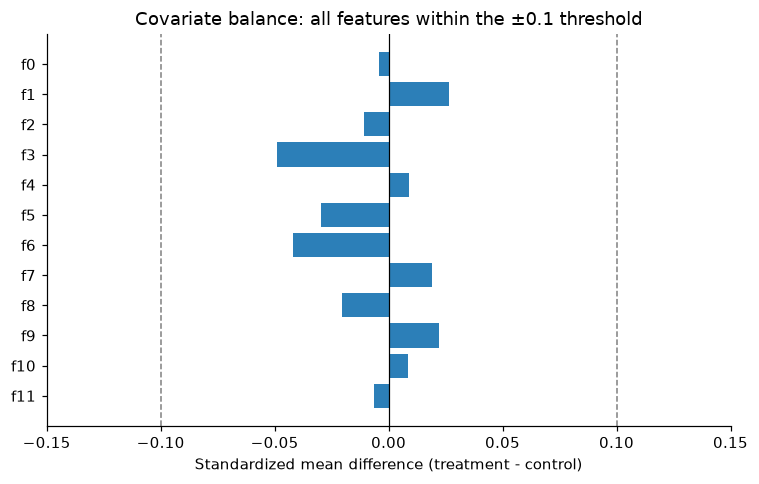

In [5]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(smd["feature"], smd["smd"], color=np.where(smd["imbalanced"], "#c0392b", "#2c7fb8"))
for x in (-0.1, 0.1):
    ax.axvline(x, color="grey", ls="--", lw=1)
ax.axvline(0, color="black", lw=0.8)
ax.invert_yaxis()
ax.set_xlim(-0.15, 0.15)
ax.set_xlabel("Standardized mean difference (treatment - control)")
ax.set_title("Covariate balance: all features within the ±0.1 threshold" if not smd["imbalanced"].any()
             else "Covariate balance: some features exceed ±0.1")
fig.tight_layout()
fig.savefig(f"{FIG}/01_covariate_balance.png", bbox_inches="tight")
plt.show()

### 2c. Exposure check
Being *assigned* to treatment doesn't guarantee seeing an ad (the user may never hit an ad auction Criteo wins).
Control users should **never** be exposed. This is "one-sided non-compliance", which matters later (Step 6) when we
estimate the effect on users who actually saw ads.

In [6]:
validity.exposure_check(df)

,n,n_exposed,exposure_rate
treatment,,,
control,209220,0,0.0000
treatment,1188739,42803,0.0360


In [7]:
exp = validity.exposure_check(df)
print(f"SRM: observed treatment share {srm['observed_treat_share']:.4f} vs 0.85 expected, p = {srm['p_value']:.3g}")
print(f"Balance: max |SMD| = {smd['smd'].abs().max():.4f} ({smd.loc[smd['smd'].abs().idxmax(), 'feature']}); "
      f"{int(smd['imbalanced'].sum())} features over 0.1")
print(f"Exposure: control exposure rate = {exp.loc['control', 'exposure_rate']:.4f} "
      f"({int(exp.loc['control', 'n_exposed'])} exposed control users); "
      f"treatment exposure rate = {exp.loc['treatment', 'exposure_rate']:.4f}")

SRM: observed treatment share 0.8503 vs 0.85 expected, p = 0.262
Balance: max |SMD| = 0.0491 (f3); 0 features over 0.1
Exposure: control exposure rate = 0.0000 (0 exposed control users); treatment exposure rate = 0.0360
